# Marketing Analytics Test Task

## Calculated KPIs

- Sessions
- Purchases
- Revenue
- Advertising Spend
- Conversion Rate (CVR)
- Average Order Value (AOV)
- Revenue per Session (RPS)
- Return on Advertising Spend (ROAS)
- Cost per Acquisition (CPA)

## Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('performance_daily.csv')


## Data preparation

In [3]:
numeric_columns = ['spend', 'sessions', 'purchases', 'revenue']
df['date'] = pd.to_datetime(df['date'])
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

## Calculate KPIs

In [4]:
df['cvr'] = df['purchases'].div(df['sessions']).where(df['sessions'].gt(0))
df['aov'] = df['revenue'].div(df['purchases']).where(df['purchases'].gt(0))
df['revenue_per_session'] = df['revenue'].div(df['sessions']).where(df['sessions'].gt(0))
df['roas'] = df['revenue'].div(df['spend']).where(df['spend'].gt(0))
df['cpa'] = df['spend'].div(df['purchases']).where(df['spend'].gt(0) & df['purchases'].gt(0))

df.head()

,date,channel,campaign_type,geo_group,spend,sessions,purchases,revenue,cvr,aov,revenue_per_session,roas,cpa
0,2024-04-01,Paid Search,Brand,Core,452.72,441,16,2251.90,0.036281,140.743750,5.106349,4.974156,28.295000
1,2024-04-01,Paid Search,Non-Brand,Core,1013.58,787,24,2976.58,0.030496,124.024167,3.782186,2.936700,42.232500
2,2024-04-01,Paid Social,Prospecting,Core,144.20,881,5,642.46,0.005675,128.492000,0.729240,4.455340,28.840000
3,2024-04-01,Paid Social,Retargeting,Core,104.91,446,7,951.47,0.015695,135.924286,2.133341,9.069393,14.987143
4,2024-04-01,Email,Email,Core,0.00,300,6,733.12,0.020000,122.186667,2.443733,NaN,NaN


Created a new column called segment, where each value is built from three columns: channel, campaign_type, and geo_group. As a result, the table contains 18 unique segment combinations and 9 KPIs to analyze.

For each segment, we have a daily time series for each of the 9 KPIs over one year. In total, this gives us 18 × 9 = 162 time series to analyze.

Instead of manually reviewing 162 charts, we will calculate different statistics and visualize them using several heatmaps.

In [5]:

df_segmented = df.copy()

channel_short = {
    'Paid Search': 'Search',
    'Paid Social': 'Social',
    'Organic Search': 'Organic',
    'Email': 'Email'
}

campaign_short = {
    'Brand': 'Brand',
    'Non-Brand': 'NB',
    'Prospecting': 'Pro',
    'Retargeting': 'Ret',
    'Email': 'Email',
    'Organic': 'Organic'
}

geo_short = {
    'Core': 'Core',
    'Non-core': 'NonC',
    'Rest': 'Rest'
}

df_segmented['channel_short'] = df_segmented['channel'].map(channel_short)
df_segmented['campaign_short'] = df_segmented['campaign_type'].map(campaign_short)
df_segmented['geo_short'] = df_segmented['geo_group'].map(geo_short)

df_segmented['segment'] = (
    df_segmented['channel_short'] + ' ' +
    df_segmented['campaign_short'] + ' ' +
    df_segmented['geo_short']
)

non_paid_mask = df_segmented['channel'].isin(['Email', 'Organic Search'])
df_segmented.loc[non_paid_mask, 'segment'] = (
    df_segmented.loc[non_paid_mask, 'channel_short'] + ' ' +
    df_segmented.loc[non_paid_mask, 'geo_short']
)

df_segmented[['channel', 'campaign_type', 'geo_group', 'segment']].drop_duplicates().sort_values('segment')

,channel,campaign_type,geo_group,segment
4,Email,Email,Core,Email Core
10,Email,Email,Non-core,Email NonC
16,Email,Email,Rest,Email Rest
5,Organic Search,Organic,Core,Organic Core
11,Organic Search,Organic,Non-core,Organic NonC
17,Organic Search,Organic,Rest,Organic Rest
0,Paid Search,Brand,Core,Search Brand Core
6,Paid Search,Brand,Non-core,Search Brand NonC
12,Paid Search,Brand,Rest,Search Brand Rest
1,Paid Search,Non-Brand,Core,Search NB Core


In [6]:
df_segmented['segment'].value_counts()

segment
Search Brand Core    365
Search NB Core       365
Social Pro Core      365
Social Ret Core      365
Email Core           365
Organic Core         365
Search Brand NonC    365
Search NB NonC       365
Social Pro NonC      365
Social Ret NonC      365
Email NonC           365
Organic NonC         365
Search Brand Rest    365
Search NB Rest       365
Social Pro Rest      365
Social Ret Rest      365
Email Rest           365
Organic Rest         365
Name: count, dtype: int64

### Heatmap of Linear Trends by Segment and KPI
Idea

For each segment × KPI pair, we take the daily time series for one year and fit a linear trend line. Then we measure how much the fitted value changes from the beginning to the end of the period.

The percentage shown in each cell is calculated as:

(Trend value at the end−Trend value at the beginning)/Trend value at the beginning×100

### Each cell contains two values:

Top (small text): the average daily value of the KPI for that segment over the year.
Bottom (large text): the percentage change of the fitted linear trend from the beginning to the end of the year.

The cell color represents only the trend percentage, not the average value.

### Interpretation
- +20% means that, according to the fitted linear trend, the KPI increased by approximately 20% over the year.
- −15% means that, according to the fitted linear trend, the KPI decreased by approximately 15% over the year.
- The average value shown at the top helps estimate the size of the segment, so that a large percentage increase in a very small segment is not mistaken for a significant business impact.
- Empty cells appear where the KPI cannot be calculated correctly, for example ROAS or CPA for channels without advertising spend, or when the fitted trend starts from zero.

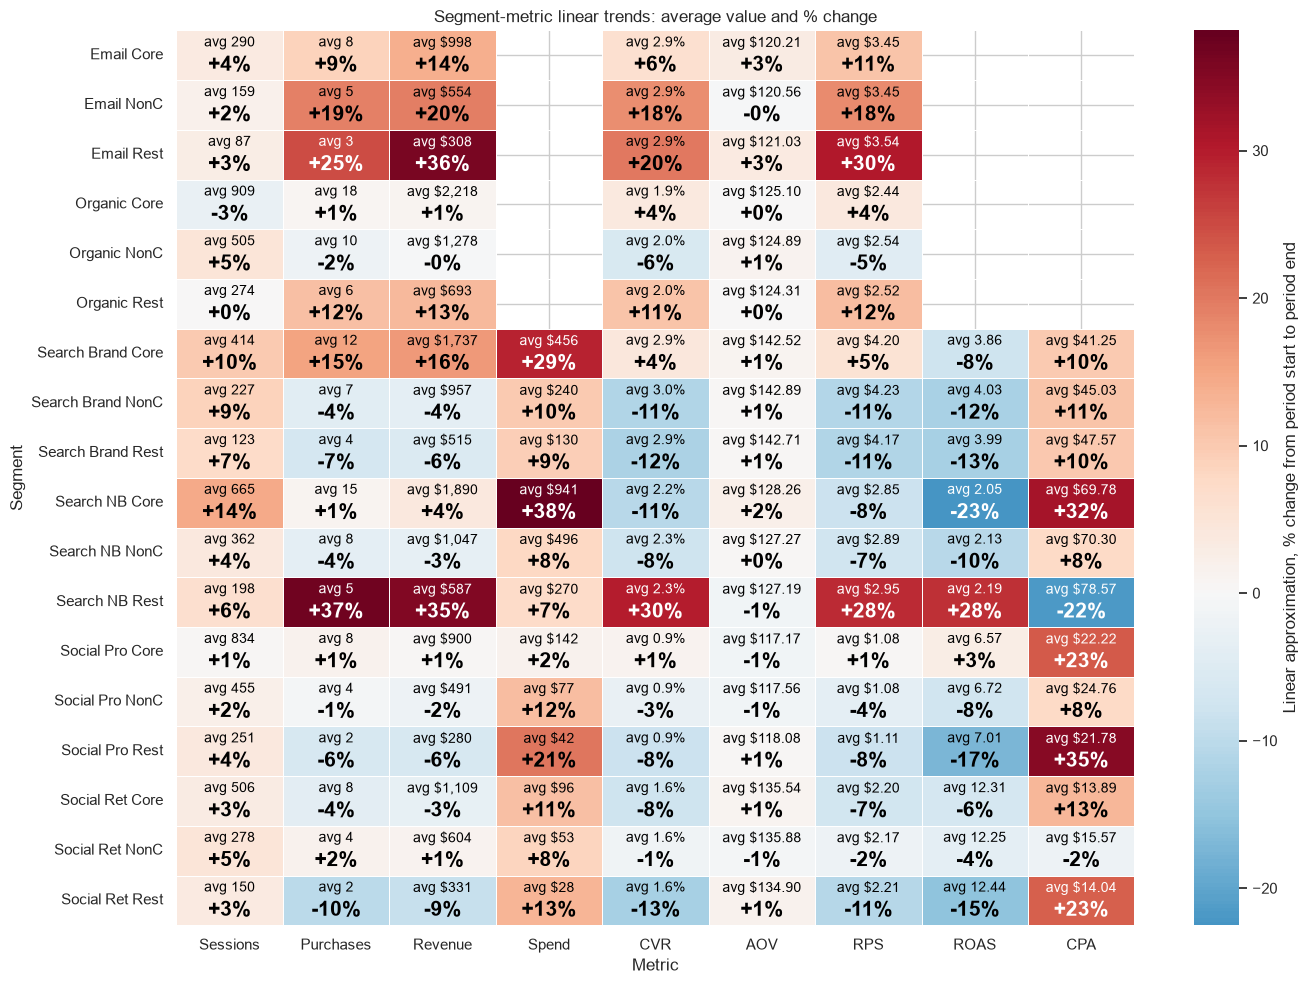

In [7]:
metrics = [
    'sessions',
    'purchases',
    'revenue',
    'spend',
    'cvr',
    'aov',
    'revenue_per_session',
    'roas',
    'cpa'
]

metric_labels = {
    'sessions': 'Sessions',
    'purchases': 'Purchases',
    'revenue': 'Revenue',
    'spend': 'Spend',
    'cvr': 'CVR',
    'aov': 'AOV',
    'revenue_per_session': 'RPS',
    'roas': 'ROAS',
    'cpa': 'CPA'
}

trend_rows = []

for segment, segment_data in df_segmented.groupby('segment'):
    segment_data = segment_data.sort_values('date').copy()
    x = (segment_data['date'] - segment_data['date'].min()).dt.days
    period_start = x.min()
    period_end = x.max()

    for metric in metrics:
        metric_data = segment_data[[metric]].copy()
        metric_data['x'] = x
        metric_data = metric_data.dropna(subset=[metric])
        mean_value = metric_data[metric].mean()

        if len(metric_data) < 2 or period_start == period_end:
            yearly_change_pct = np.nan
        else:
            slope, intercept = np.polyfit(metric_data['x'], metric_data[metric], 1)

            start_value = slope * period_start + intercept
            end_value = slope * period_end + intercept

            if pd.isna(start_value) or np.isclose(start_value, 0) or start_value <= 0:
                yearly_change_pct = np.nan
            else:
                yearly_change_pct = ((end_value - start_value) / start_value) * 100

        trend_rows.append({
            'segment': segment,
            'metric': metric_labels[metric],
            'yearly_change_pct': yearly_change_pct,
            'mean_value': mean_value
        })

trend_table = pd.DataFrame(trend_rows)

trend_heatmap = trend_table.pivot(
    index='segment',
    columns='metric',
    values='yearly_change_pct'
)
trend_heatmap = trend_heatmap[[metric_labels[metric] for metric in metrics]]

mean_heatmap = trend_table.pivot(
    index='segment',
    columns='metric',
    values='mean_value'
)
mean_heatmap = mean_heatmap[[metric_labels[metric] for metric in metrics]]


def format_mean_value(value, metric_label):
    if pd.isna(value):
        return ''
    if metric_label in ['CVR']:
        return f'avg {value:.1%}'
    if metric_label in ['Revenue', 'Spend']:
        return f'avg ${value:,.0f}'
    if metric_label in ['AOV', 'RPS', 'CPA']:
        return f'avg ${value:,.2f}'
    if metric_label == 'ROAS':
        return f'avg {value:.2f}'
    return f'avg {value:,.0f}'

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    trend_heatmap,
    cmap='RdBu_r',
    center=0,
    annot=False,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Linear approximation, % change from period start to period end'}
)

max_abs_pct = np.nanmax(np.abs(trend_heatmap.to_numpy()))

for row_index, segment in enumerate(trend_heatmap.index):
    for col_index, metric_label in enumerate(trend_heatmap.columns):
        pct_value = trend_heatmap.loc[segment, metric_label]
        mean_value = mean_heatmap.loc[segment, metric_label]

        if pd.isna(pct_value):
            continue

        text_color = 'white' if abs(pct_value) > max_abs_pct * 0.55 else 'black'

        ax.text(
            col_index + 0.5,
            row_index + 0.25,
            format_mean_value(mean_value, metric_label),
            ha='center',
            va='center',
            fontsize=10,
            color=text_color
        )
        ax.text(
            col_index + 0.5,
            row_index + 0.70,
            f'{pct_value:+.0f}%',
            ha='center',
            va='center',
            fontsize=15,
            fontweight='bold',
            color=text_color
        )

plt.title('Segment-metric linear trends: average value and % change')
plt.xlabel('Metric')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

### Trend investigation

The heatmap helps identify segments with the strongest positive and negative long-term trends.

One of the most noticeable examples is Search NB Core.

This segment shows:

- Spend increased by 38%;
- Revenue increased by only 4%;
- ROAS decreased by 23%;
- CPA increased by 32%.

This indicates that advertising efficiency gradually declined throughout the year. The company spent significantly more money, while business outcomes remained almost unchanged.

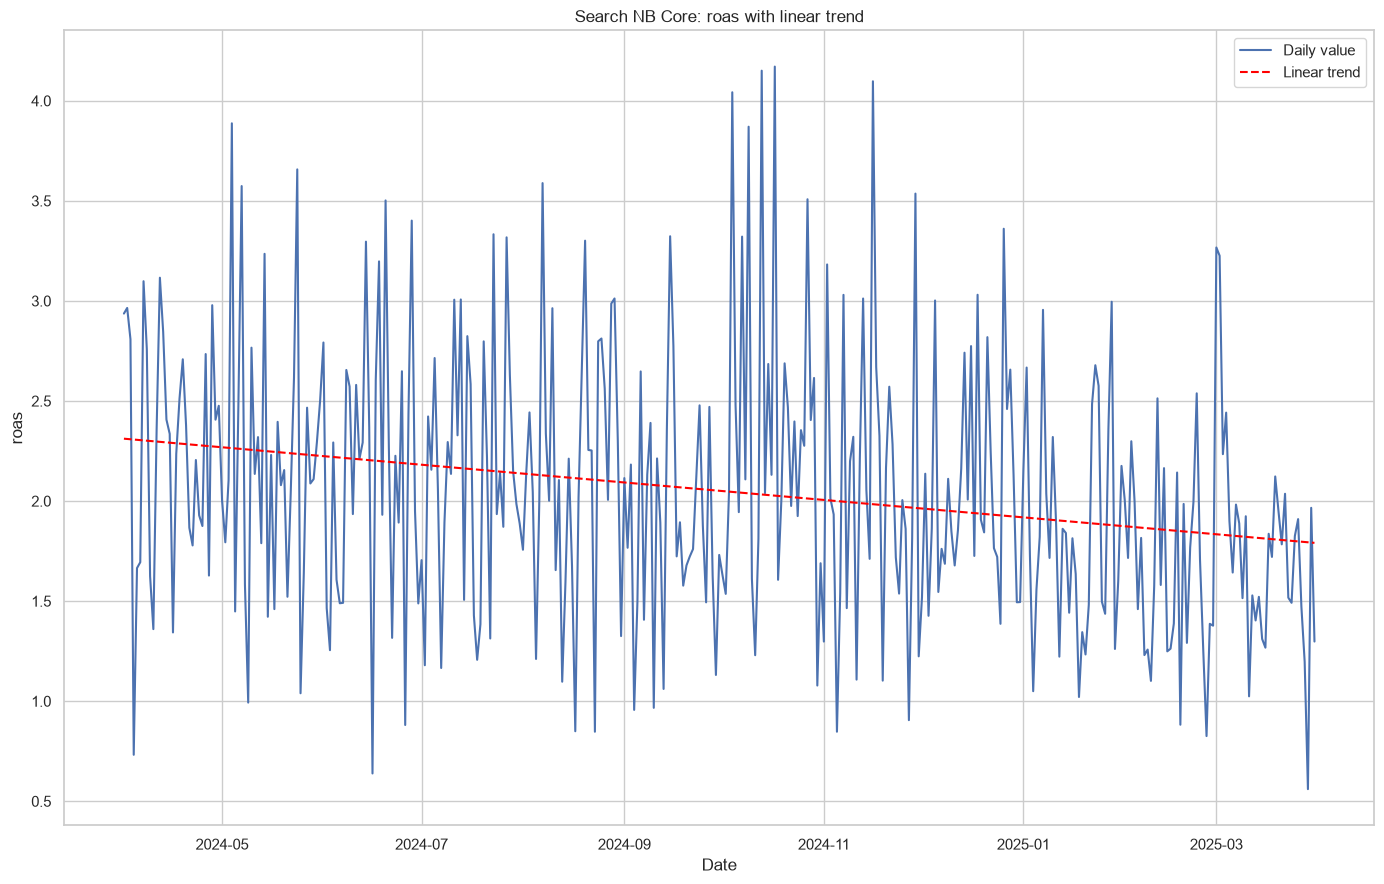

In [8]:
segment_to_plot = 'Search NB Core'
metric_to_plot = 'roas'

plot_data = (
    df_segmented[df_segmented['segment'] == segment_to_plot]
    .sort_values('date')
    .dropna(subset=[metric_to_plot])
    .copy()
)

plot_data['day_number'] = (plot_data['date'] - plot_data['date'].min()).dt.days
slope, intercept = np.polyfit(plot_data['day_number'], plot_data[metric_to_plot], 1)
plot_data['trend_line'] = slope * plot_data['day_number'] + intercept

plt.figure(figsize=(14, 9))

sns.lineplot(
    data=plot_data,
    x='date',
    y=metric_to_plot,
    label='Daily value'
)

sns.lineplot(
    data=plot_data,
    x='date',
    y='trend_line',
    linestyle='--',
    color='red',
    label='Linear trend'
)

plt.title(f'{segment_to_plot}: {metric_to_plot} with linear trend')
plt.xlabel('Date')
plt.ylabel(metric_to_plot)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Trend break

The linear heatmap above shows the overall growth or decline of each metric over the year. However, it does not capture situations where the trend direction changed inside the period: for example, when a metric first increased and then started to decline, or the opposite.

To find candidates for such trend breaks, we approximate each segment × metric time series with a parabola:

y = ax² + bx + c

I approximate each time series with a parabola and then measure its curvature to detect possible trend breaks.

The sign is easy to interpret:

positive value: U-shape, the middle is lower than the edges, possible bottom-up reversal;
negative value: inverted U-shape, the middle is higher than the edges, possible top-down reversal;
value close to zero: no clear curvature, the series is closer to a straight line.

This heatmap does not prove the reason for the change, but it helps quickly identify segments and metrics where the shape of the time series looks like a reversal or a trend break inside the year.

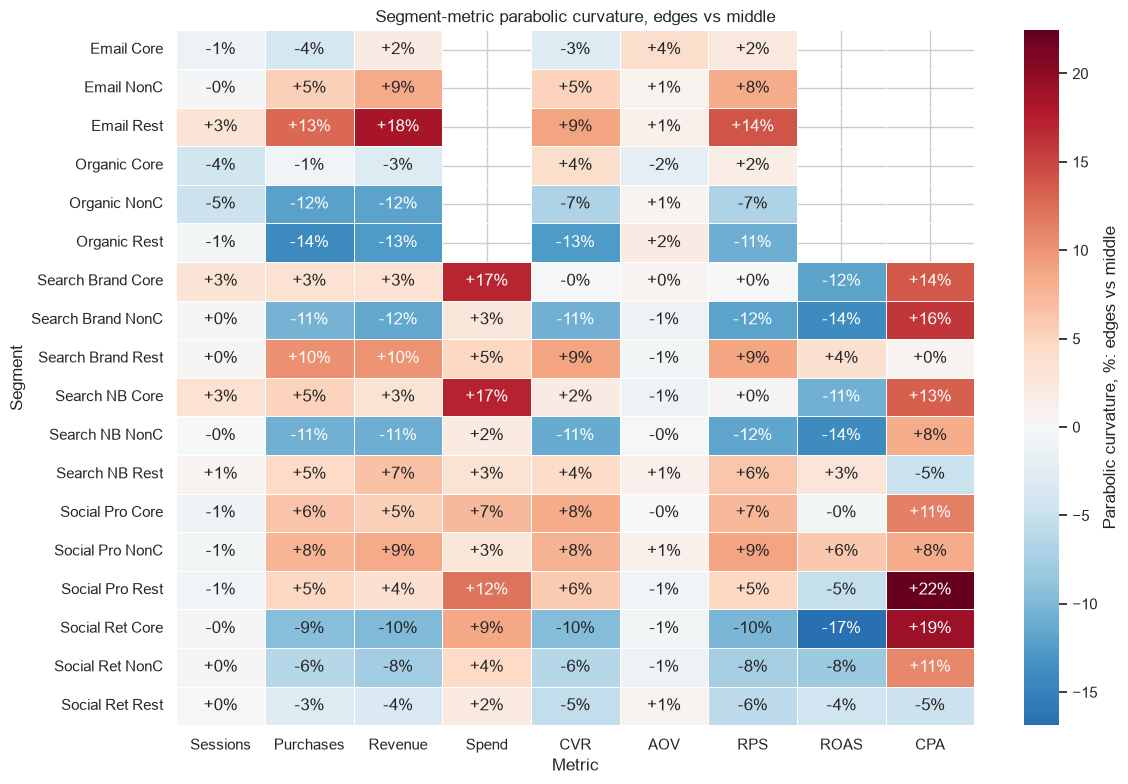

In [9]:
curvature_rows = []

for segment, segment_data in df_segmented.groupby('segment'):
    segment_data = segment_data.sort_values('date').copy()
    day_number = (segment_data['date'] - segment_data['date'].min()).dt.days
    period_length = day_number.max() - day_number.min()

    if period_length == 0:
        continue

    x_normalized = 2 * (day_number - day_number.min()) / period_length - 1

    for metric in metrics:
        metric_data = segment_data[[metric]].copy()
        metric_data['x_normalized'] = x_normalized
        metric_data = metric_data.dropna(subset=[metric])

        if len(metric_data) < 3:
            curvature_pct = np.nan
        else:
            a, b, c = np.polyfit(
                metric_data['x_normalized'],
                metric_data[metric],
                2
            )

            middle_value = c
            edge_mean_value = (a * (-1) ** 2 + b * (-1) + c + a * 1 ** 2 + b * 1 + c) / 2

            if pd.isna(middle_value) or np.isclose(middle_value, 0) or middle_value <= 0:
                curvature_pct = np.nan
            else:
                curvature_pct = ((edge_mean_value - middle_value) / middle_value) * 100

        curvature_rows.append({
            'segment': segment,
            'metric': metric_labels[metric],
            'curvature_pct': curvature_pct
        })

curvature_table = pd.DataFrame(curvature_rows)
curvature_heatmap = curvature_table.pivot(
    index='segment',
    columns='metric',
    values='curvature_pct'
)
curvature_heatmap = curvature_heatmap[[metric_labels[metric] for metric in metrics]]

curvature_labels = curvature_heatmap.map(
    lambda value: '' if pd.isna(value) else f'{value:+.0f}%'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    curvature_heatmap,
    cmap='RdBu_r',
    center=0,
    annot=curvature_labels,
    fmt='',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Parabolic curvature, %: edges vs middle'}
)

plt.title('Segment-metric parabolic curvature, edges vs middle')
plt.xlabel('Metric')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

### No significant trend breaks were found in the heatmap.

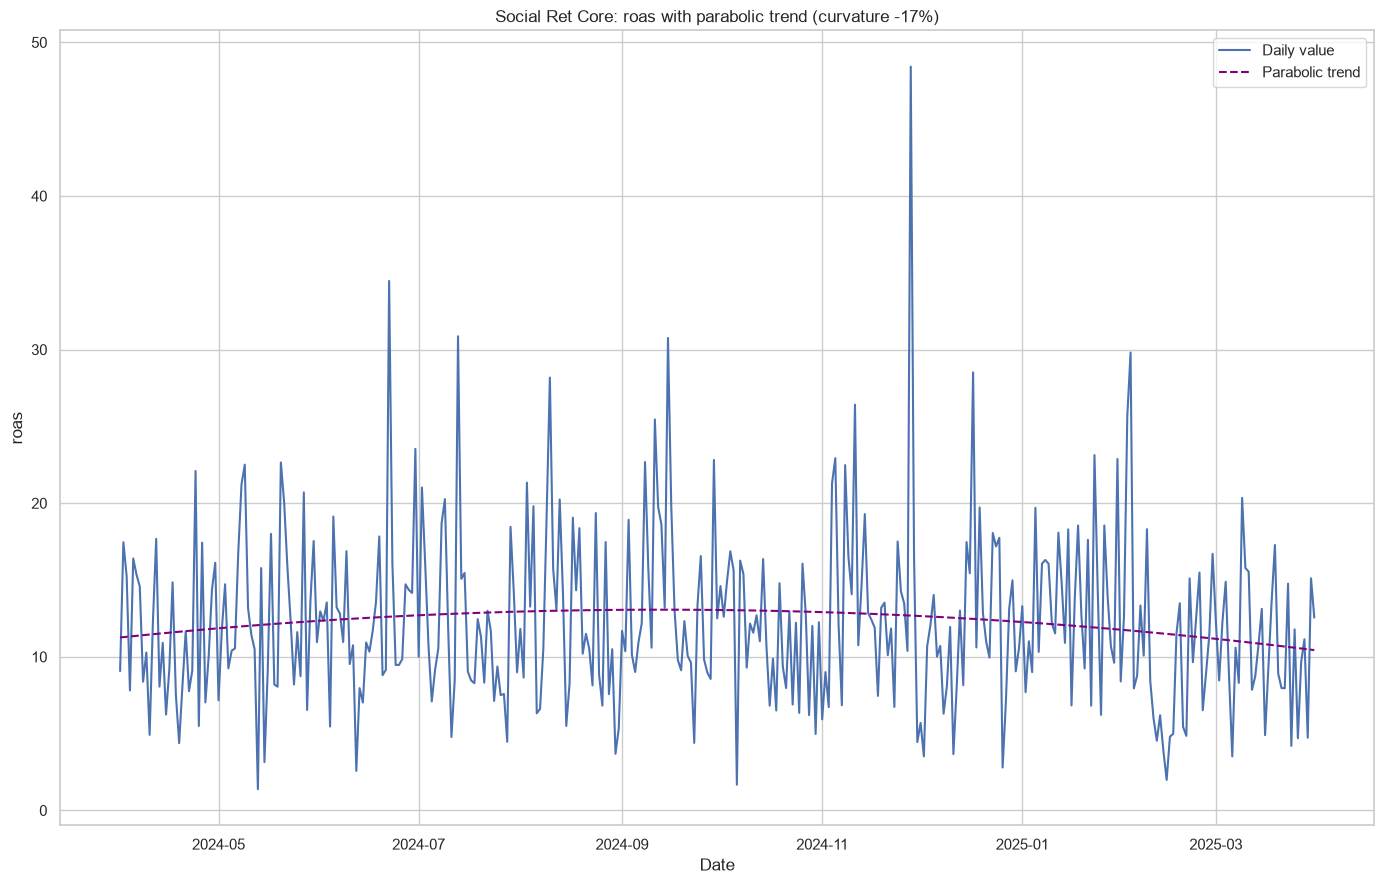

In [10]:
segment_to_plot = 'Social Ret Core'
metric_to_plot = 'roas'

plot_data = (
    df_segmented[df_segmented['segment'] == segment_to_plot]
    .sort_values('date')
    .dropna(subset=[metric_to_plot])
    .copy()
)

plot_data['day_number'] = (plot_data['date'] - plot_data['date'].min()).dt.days
period_length = plot_data['day_number'].max() - plot_data['day_number'].min()
plot_data['x_normalized'] = 2 * plot_data['day_number'] / period_length - 1

a, b, c = np.polyfit(plot_data['x_normalized'], plot_data[metric_to_plot], 2)
plot_data['parabola_trend'] = a * plot_data['x_normalized'] ** 2 + b * plot_data['x_normalized'] + c

middle_value = c
edge_mean_value = (a * (-1) ** 2 + b * (-1) + c + a * 1 ** 2 + b * 1 + c) / 2
curvature_pct = ((edge_mean_value - middle_value) / middle_value) * 100

plt.figure(figsize=(14, 9))

sns.lineplot(
    data=plot_data,
    x='date',
    y=metric_to_plot,
    label='Daily value'
)

sns.lineplot(
    data=plot_data,
    x='date',
    y='parabola_trend',
    linestyle='--',
    color='purple',
    label='Parabolic trend'
)

plt.title(
    f'{segment_to_plot}: {metric_to_plot} with parabolic trend '
    f'(curvature {curvature_pct:+.0f}%)'
)
plt.xlabel('Date')
plt.ylabel(metric_to_plot)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Heatmap of anomalies by segment and KPI

The last type of change is an anomaly an unusual spike or drop on a specific day.

Linear and parabolic trends describe the overall behavior of a KPI during the year, but they may miss short-term events. This heatmap is designed to find those unusual points.

For each segment × KPI pair, I compare each daily value with its typical level over the surrounding days. This allows me to identify days where the KPI behaves very differently from normal.

### For every segment and KPI, the heatmap shows:

the strongest anomaly score;
the date when it happened.

The sign of the score is easy to interpret:

- Positive value — an unusually high spike.
- Negative value — an unusually low drop.
- The larger the absolute value, the stronger the anomaly.

For example, −4.1σ / Feb 12 means that a strong negative anomaly occurred on February 12.

This heatmap helps quickly identify segments and KPIs that deserve a closer investigation.

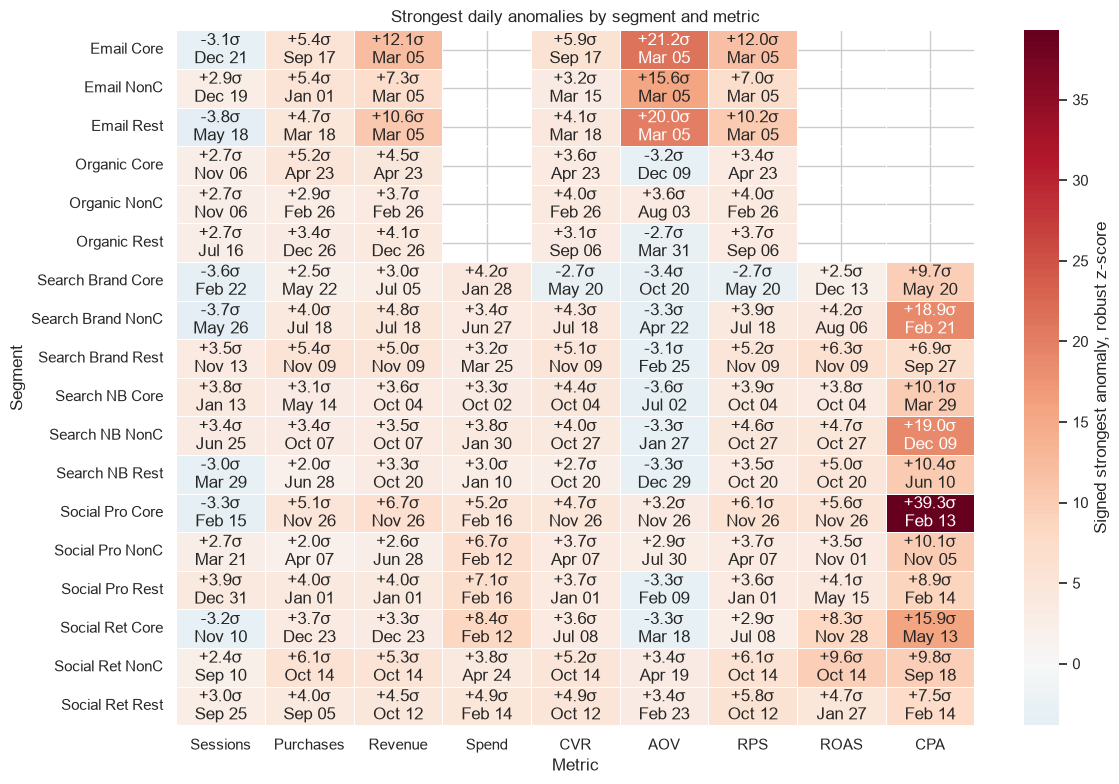

In [11]:
anomaly_rows = []
rolling_window = 21
min_periods = 7

for segment, segment_data in df_segmented.groupby('segment'):
    segment_data = segment_data.sort_values('date').copy()

    for metric in metrics:
        metric_data = segment_data[['date', metric]].dropna(subset=[metric]).copy()

        if len(metric_data) < min_periods:
            anomaly_score = np.nan
            anomaly_date = pd.NaT
        else:
            metric_data['baseline'] = metric_data[metric].rolling(
                window=rolling_window,
                center=True,
                min_periods=min_periods
            ).median()

            metric_data['residual'] = metric_data[metric] - metric_data['baseline']
            residual_median = metric_data['residual'].median()
            mad = (metric_data['residual'] - residual_median).abs().median()
            robust_sigma = 1.4826 * mad

            if pd.isna(robust_sigma) or np.isclose(robust_sigma, 0):
                anomaly_score = np.nan
                anomaly_date = pd.NaT
            else:
                metric_data['robust_z'] = metric_data['residual'] / robust_sigma
                anomaly_index = metric_data['robust_z'].abs().idxmax()
                anomaly_score = metric_data.loc[anomaly_index, 'robust_z']
                anomaly_date = metric_data.loc[anomaly_index, 'date']

        anomaly_rows.append({
            'segment': segment,
            'metric': metric_labels[metric],
            'anomaly_score': anomaly_score,
            'anomaly_date': anomaly_date
        })

anomaly_table = pd.DataFrame(anomaly_rows)
anomaly_heatmap = anomaly_table.pivot(
    index='segment',
    columns='metric',
    values='anomaly_score'
)
anomaly_heatmap = anomaly_heatmap[[metric_labels[metric] for metric in metrics]]

anomaly_dates = anomaly_table.pivot(
    index='segment',
    columns='metric',
    values='anomaly_date'
)
anomaly_dates = anomaly_dates[[metric_labels[metric] for metric in metrics]]

anomaly_labels = anomaly_heatmap.copy().astype(object)
for segment in anomaly_heatmap.index:
    for metric_label in anomaly_heatmap.columns:
        score = anomaly_heatmap.loc[segment, metric_label]
        date = anomaly_dates.loc[segment, metric_label]

        if pd.isna(score) or pd.isna(date):
            anomaly_labels.loc[segment, metric_label] = ''
        else:
            anomaly_labels.loc[segment, metric_label] = f'{score:+.1f}σ\n{date:%b %d}'

plt.figure(figsize=(12, 8))
sns.heatmap(
    anomaly_heatmap,
    cmap='RdBu_r',
    center=0,
    annot=anomaly_labels,
    fmt='',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Signed strongest anomaly, robust z-score'}
)

plt.title('Strongest daily anomalies by segment and metric')
plt.xlabel('Metric')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

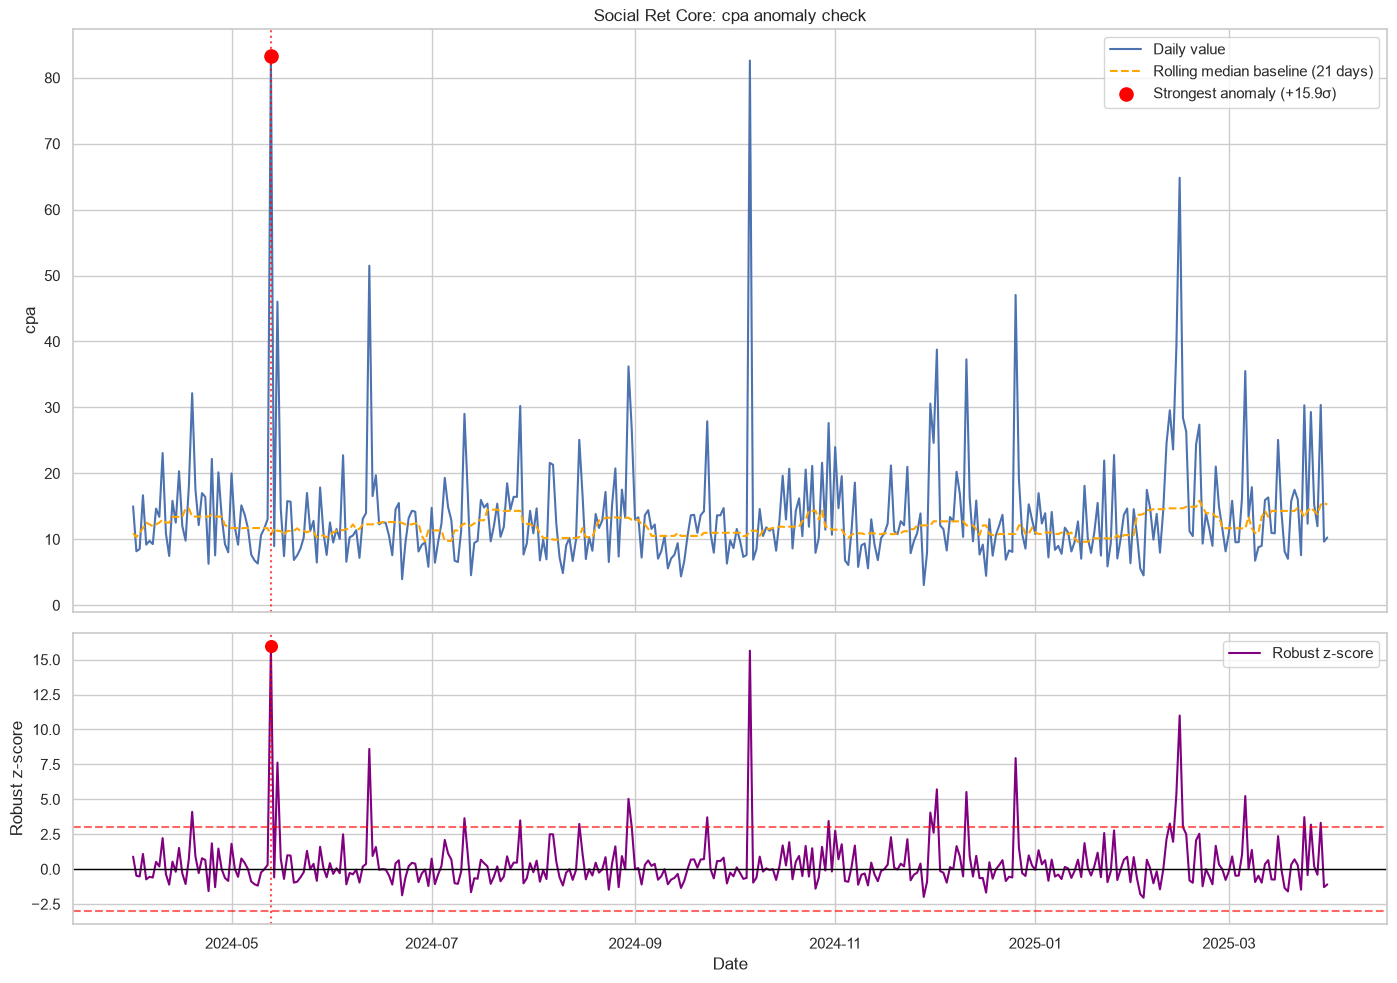

In [12]:
segment_to_plot = 'Social Ret Core'
metric_to_plot = 'cpa'

plot_data = (
    df_segmented[df_segmented['segment'] == segment_to_plot][['date', metric_to_plot]]
    .sort_values('date')
    .dropna(subset=[metric_to_plot])
    .copy()
)

plot_data['baseline'] = plot_data[metric_to_plot].rolling(
    window=rolling_window,
    center=True,
    min_periods=min_periods
).median()

plot_data['residual'] = plot_data[metric_to_plot] - plot_data['baseline']
residual_median = plot_data['residual'].median()
mad = (plot_data['residual'] - residual_median).abs().median()
robust_sigma = 1.4826 * mad
plot_data['robust_z'] = plot_data['residual'] / robust_sigma

anomaly_index = plot_data['robust_z'].abs().idxmax()
anomaly_date = plot_data.loc[anomaly_index, 'date']
anomaly_value = plot_data.loc[anomaly_index, metric_to_plot]
anomaly_score = plot_data.loc[anomaly_index, 'robust_z']

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(14, 10),
    sharex=True,
    gridspec_kw={'height_ratios': [2, 1]}
)

sns.lineplot(
    data=plot_data,
    x='date',
    y=metric_to_plot,
    ax=axes[0],
    label='Daily value'
)

sns.lineplot(
    data=plot_data,
    x='date',
    y='baseline',
    ax=axes[0],
    color='orange',
    linestyle='--',
    label=f'Rolling median baseline ({rolling_window} days)'
)

axes[0].scatter(
    anomaly_date,
    anomaly_value,
    color='red',
    s=90,
    zorder=5,
    label=f'Strongest anomaly ({anomaly_score:+.1f}σ)'
)

axes[0].axvline(anomaly_date, color='red', linestyle=':', alpha=0.7)
axes[0].set_title(f'{segment_to_plot}: {metric_to_plot} anomaly check')
axes[0].set_ylabel(metric_to_plot)
axes[0].grid(True)
axes[0].legend()

sns.lineplot(
    data=plot_data,
    x='date',
    y='robust_z',
    ax=axes[1],
    color='purple',
    label='Robust z-score'
)

axes[1].axhline(0, color='black', linewidth=1)
axes[1].axhline(3, color='red', linestyle='--', alpha=0.6)
axes[1].axhline(-3, color='red', linestyle='--', alpha=0.6)
axes[1].axvline(anomaly_date, color='red', linestyle=':', alpha=0.7)
axes[1].scatter(
    anomaly_date,
    anomaly_score,
    color='red',
    s=70,
    zorder=5
)
axes[1].set_ylabel('Robust z-score')
axes[1].set_xlabel('Date')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()